# Solaris

## Imports

In [1]:
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import VecNormalize, DummyVecEnv
from IPython.display import clear_output, display
from contextlib import contextmanager
from dataclasses import dataclass
from stable_baselines3 import PPO
import matplotlib.pyplot as plt
import gymnasium as gym
import numpy as np
import ale_py
import pygame
import time

## Helper functions

In [2]:
# See the preprocessing section where these values have been chosen
def trim_frame(frame):
    return frame[2:-13, 8:, :]

## Environment

In [3]:
# I will use context managers for managing the environment to ensure that it will be reset and closed
WINDOW_SIZE = (455, 580)

@contextmanager
def create_env(env_name, live_rendering=False, **kwargs):
    env = gym.make(env_name, **kwargs)
    env.reset()
    env.__setattr__('_live_rendering', live_rendering)

    if live_rendering:
        if env.render_mode != 'rgb_array':
            raise ValueError('Render mode should be rgb_array for live rendering')
        
        pygame.init()
        pygame.display.set_caption(env_name)
        pygame.event.set_allowed([pygame.QUIT, pygame.KEYDOWN])

        env.__setattr__('_clock', pygame.time.Clock())
        env.__setattr__('_screen', pygame.display.set_mode(WINDOW_SIZE, pygame.RESIZABLE))
    try:
        yield env
    finally:
        env.close()

        if live_rendering:
            pygame.quit()

# I will also use a dataclass for episode to keep the loop cleaner
@dataclass
class Episode:
    env: gym.Env
    
    obs: object = None
    reward: float | None = None
    terminated: bool = False
    truncated: bool = False
    info: dict | None = None

    stop_rendering = False

    def _render(self):
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                self.stop_rendering = True

                return

        screen = self.env.__getattribute__('_screen')
        frame = trim_frame(self.env.render())
        
        raw_surface = pygame.surfarray.make_surface(np.transpose(frame, (1, 0, 2)))
        upscaled_surface = pygame.transform.scale_by(raw_surface, 3)

        scr_w, scr_h = screen.get_size()
        surf_w, surf_h = upscaled_surface.get_size()
        
        x_offset = (scr_w - surf_w) // 2
        y_offset = (scr_h - surf_h) // 2

        screen.fill((0, 0, 0))
        screen.blit(upscaled_surface, (x_offset, y_offset))

        pygame.display.flip()

        self.env.__getattribute__('_clock').tick(60)

    @property
    def done(self):
        return self.terminated or self.truncated or self.stop_rendering
    
    def step(self, action):
        self.obs, self.reward, self.terminated, self.truncated, self.info = self.env.step(action)

        if not self.done and self.env.__getattribute__('_live_rendering'):
            self._render()

@contextmanager
def create_episode(env, **kwargs):
    obs, info = env.reset(**kwargs)

    yield Episode(env, obs=obs, info=info)

In [ ]:
# Testing the live rendering
if False:
    with create_env('ALE/Solaris-v5', live_rendering=True, render_mode='rgb_array') as env:
        for _ in range(10):
            with create_episode(env) as episode:
                while not episode.done:
                    action = env.action_space.sample()
                    episode.step(action)

                if episode.stop_rendering:
                    break

## Preprocessing

In [ ]:
# Let's first check what the input looks like
if False:
    with create_env('ALE/Solaris-v5', render_mode='rgb_array') as env:
        print(f'Action Space: {env.action_space}')
        print(f'State space: {env.observation_space}')

        plt.imshow(env.render())

```python
Action Space: Discrete(18)
State space: Box(0, 255, (210, 160, 3), uint8)
```

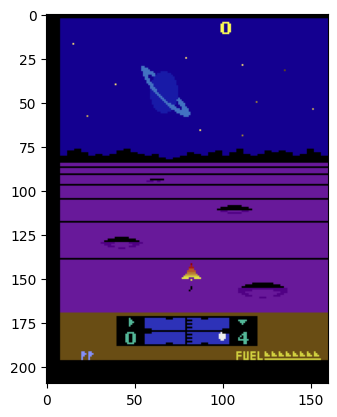  

In [21]:
# The game state appears to have some black padding.
# We will trim these pixels.
# The function is defined above so it can be used for live rendering.
if False: 
    with create_env('ALE/Solaris-v5', render_mode='rgb_array') as env:
        # TODO change to actual observation
        plt.imshow(env.render()[2:-13, 8:, :])

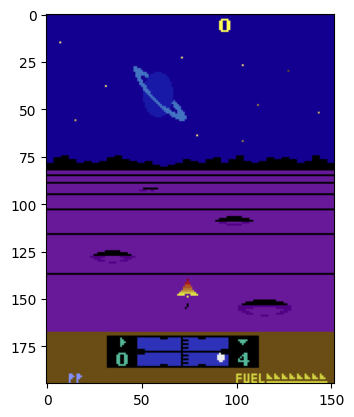

In [22]:
# Looking back at the solaris page on the gymnasium website there is an alternative observation space that is just 128 values.
# This is because the Atari 2600 only had 128 bytes of RAM and with this mode the agent has direct access to these values.
if False:
    with create_env('ALE/Solaris-v5', obs_type='ram') as env:
        print(f'Action Space: {env.action_space}')
        print(f'State space: {env.observation_space}')

```python
Action Space: Discrete(18)
State space: Box(0, 255, (128,), uint8)
```

In [8]:
# There is a caveat with this approach and that is that due to the limited RAM the same slots can be used for different things
# depending on the current game state. The usage of the slot for multiple things is not that big of an issue itself since 
# the network can act on this using the game state but for the network to be able to filter the value the game state should be 
# one-hot encoded.

# I found a copy of the source code of the game online (https://forums.atariage.com/topic/64694-original-source-code/).
# The RAM addresses within the console start at 0x80 so we will subtract this for the indices of the array.
ADDRESS_OFFSET = 0x80

def display_state(env, ram, clear=True):
    frame = env.render()
    ram_grid = ram.reshape((16, 8))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.imshow(trim_frame(frame))
    ax1.axis('off')

    im = ax2.imshow(ram_grid, cmap='viridis', vmin=0, vmax=255)
    ax2.set_title('RAM State')

    for i in range(16):
        for j in range(8):
            location = i * 8 + j + ADDRESS_OFFSET
            color = 'white' if ram_grid[i, j] < 128 else 'black'

            ax2.text(j, i, hex(location), ha='center', va='center', fontsize=7, color=color, alpha=0.5)
            
    plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

    if clear:
        clear_output(wait=True)
    
    display(plt.gcf())
    plt.close(fig)

    for i in range(16):
        for j in range(8):
            print(f'{hex(i * 8 + j + ADDRESS_OFFSET)}: {ram_grid[i, j]:>3}, ', end='')

        print()

In [23]:
if False:
    with create_env('ALE/Solaris-v5', obs_type='ram', render_mode='rgb_array') as env:
        with create_episode(env) as episode:
            while not episode.done:
                action = env.action_space.sample()
                episode.step(action)
                display_state(env, episode.obs)

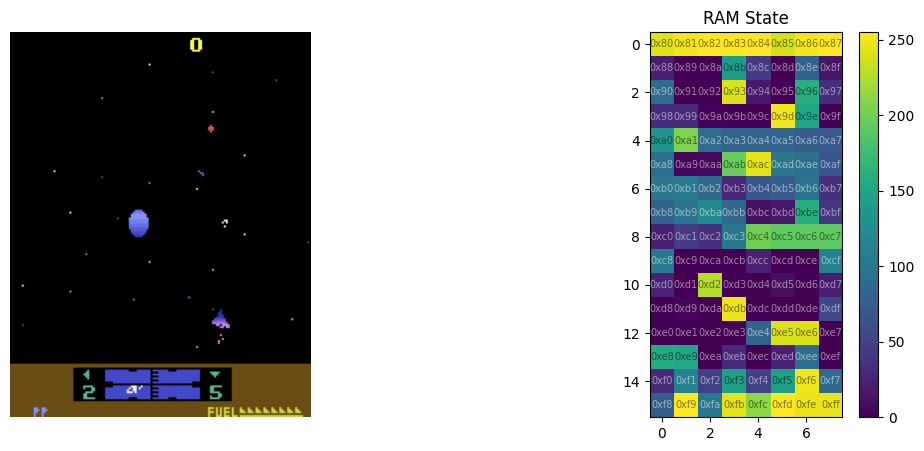

```python
0x80: 243, 0x81: 251, 0x82: 255, 0x83: 254, 0x84: 255, 0x85: 239, 0x86: 251, 0x87: 255, 
0x88:  21, 0x89:   0, 0x8a:   0, 0x8b: 140, 0x8c:  43, 0x8d:   0, 0x8e:  78, 0x8f:  14, 
0x90:  89, 0x91:   0, 0x92:   0, 0x93: 241, 0x94:  17, 0x95:   0, 0x96: 160, 0x97:  32, 
0x98:  32, 0x99:  30, 0x9a:   2, 0x9b:   1, 0x9c:   0, 0x9d: 250, 0x9e: 151, 0x9f:   0, 
0xa0: 133, 0xa1: 206, 0xa2:  90, 0xa3:  83, 0xa4:  83, 0xa5:  83, 0xa6:  75, 0xa7:  71, 
0xa8:  93, 0xa9:   4, 0xaa:   5, 0xab: 196, 0xac: 245, 0xad: 101, 0xae:  94, 0xaf:  68, 
0xb0: 101, 0xb1: 105, 0xb2:  88, 0xb3:  29, 0xb4:  67, 0xb5:  74, 0xb6:  97, 0xb7:  34, 
0xb8:  78, 0xb9:  98, 0xba: 121, 0xbb:  86, 0xbc:  11, 0xbd:  16, 0xbe: 160, 0xbf:  38, 
0xc0:  21, 0xc1:  45, 0xc2:  34, 0xc3: 102, 0xc4: 200, 0xc5: 192, 0xc6: 192, 0xc7: 192, 
0xc8: 104, 0xc9:   0, 0xca:   0, 0xcb:   0, 0xcc:  23, 0xcd:   0, 0xce:   0, 0xcf: 112, 
0xd0:  24, 0xd1:   0, 0xd2: 227, 0xd3:   0, 0xd4:   0, 0xd5:  10, 0xd6:   0, 0xd7:  21, 
0xd8:   0, 0xd9:   3, 0xda:   1, 0xdb: 248, 0xdc:   0, 0xdd:   0, 0xde:   0, 0xdf:  55, 
0xe0:   0, 0xe1:   0, 0xe2:   0, 0xe3:   0, 0xe4:  82, 0xe5: 240, 0xe6: 242, 0xe7:   0, 
0xe8: 157, 0xe9: 152, 0xea:   0, 0xeb:  31, 0xec:   0, 0xed:  23, 0xee:  89, 0xef:   0, 
0xf0:  30, 0xf1: 112, 0xf2:  48, 0xf3: 144, 0xf4:  48, 0xf5: 144, 0xf6: 250, 0xf7:  88, 
0xf8:  75, 0xf9: 255, 0xfa: 102, 0xfb: 245, 0xfc: 212, 0xfd: 255, 0xfe: 248, 0xff: 248,
```

In [24]:
# I will use these techniques to figure out what each address corresponds to: 
# https://github.com/mila-iqia/atari-representation-learning/blob/master/notebooks/atari_guess_n_check.ipynb
ACTIONS = {
    'NOOP': 0,
    'FIRE': 1,
    'UP': 2,
    'RIGHT': 3,
    'LEFT': 4,
    'DOWN': 5,
    'UPRIGHT': 6,
    'UPLEFT': 7,
    'DOWNRIGHT': 8,
    'DOWNLEFT': 9,
    'UPFIRE': 10,
    'RIGHTFIRE': 11,
    'LEFTFIRE': 12,
    'DOWNFIRE': 13,
    'UPRIGHTFIRE': 14,
    'UPLEFTFIRE': 15,
    'DOWNRIGHTFIRE': 16,
    'DOWNLEFTFIRE': 17,
}

if False:
    with create_env('ALE/Solaris-v5', obs_type='ram', render_mode='rgb_array') as env:
        with create_episode(env) as episode:
            display_state(env, episode.obs, clear=False)
            episode.step(ACTIONS['NOOP'])
            display_state(env, episode.obs, clear=False)

In [11]:
ADDRESSES = [
    0x92, # PNTR 1
    0x93, # PNTR 1
    0x94, # PNTR 2
    0x95, # PNTR 2
    0x96, # PNTR 3
    0x97, # PNTR 3
    0x98, # PNTR 4
    0x99, # PNTR 4
    0x9A, # PNTR 5
    0x9B, # PNTR 5
    0x9C, # PNTR 6
    0x9D, # PNTR 6
]

In [25]:
if False:
    with create_env('ALE/Solaris-v5', obs_type='ram', render_mode='rgb_array') as env:
        with create_episode(env) as episode:
                while not episode.done:
                    episode.step(ACTIONS['FIRE'])
                    display_state(env, episode.obs)
                    episode.step(ACTIONS['NOOP'])
                    display_state(env, episode.obs)

## Reinforcement Learning
Since the state space is really large (and continuous for the ram version), it won't be a good idea (or possible) to use Q-learning or SARSA since these need every state to be visited (and often multiple times) making it really slow to train. They also need at least 1 action to select per state so the memory requirements will be really large. 

For models using gradient updates it will be important to use a scaling mechanism for the RAM observations since some values have larger ranges than other. Normalized rewards also help gradient descend and ascend. For systems like NEAT this isn't an issue since the parameters are derived from random mutations in the evolution process.

The first method that I would like to try is PPO since it is considered one of the best reinforcement learning algorithms and it requires minimal hyperparameter tuning.

If we had more time for this project I would have loved to try a hybrid approach where the dogfighting is handled by a model-free agent using deep learning and the navigation through the galaxy by an A* algorithm using heuristics to get to Solaris as fast as possible.

## PPO

In [17]:
train_env = make_vec_env('ALE/Solaris-v5', n_envs=4, env_kwargs={'obs_type': 'ram'})
train_env = VecNormalize(train_env)
model = PPO('MlpPolicy', train_env, device='cpu', tensorboard_log='./ppo_solaris_logs/')
model.learn(total_timesteps=2_000_000)
model.save('solaris_ppo_ram')
train_env.save('solaris_vec_normalize.pkl')

In [20]:
env = make_vec_env('ALE/Solaris-v5', n_envs=4, env_kwargs={'obs_type': 'ram'})
env = VecNormalize.load('solaris_vec_normalize.pkl', env)
model = PPO.load('solaris_ppo_ram', env=env, device='cpu', tensorboard_log='./ppo_solaris_logs/')
model.learn(total_timesteps=2_000_000, reset_num_timesteps=False, tb_log_name='PPO_2')
model.save('solaris_ppo_ram_2')
env.save('solaris_vec_normalize_2.pkl')

In [27]:
env = make_vec_env('ALE/Solaris-v5', n_envs=4, env_kwargs={'obs_type': 'ram'})
env = VecNormalize.load('solaris_vec_normalize_2.pkl', env)
model = PPO.load('solaris_ppo_ram_2', env=env, device='cpu', tensorboard_log='./ppo_solaris_logs/')
model.learn(total_timesteps=6_000_000, reset_num_timesteps=False, tb_log_name='PPO_2')
model.save('solaris_ppo_ram_3')
env.save('solaris_vec_normalize_3.pkl')

In [ ]:
train_env = make_vec_env('ALE/Solaris-v5', n_envs=4, env_kwargs={'obs_type': 'ram'})
train_env = VecNormalize(train_env)

model = PPO('MlpPolicy', train_env, device='cpu', tensorboard_log='./runs/ppo_solaris_logs/')
model.learn(total_timesteps=10_000_000)

model.save('runs/ppo/solaris_ppo_ram')
train_env.save('runs/ppo/solaris_vec_normalize.pkl')

In [23]:
evaluate_policy(model, env, n_eval_episodes=100)

KeyboardInterrupt: 

In [29]:
dummy_env = DummyVecEnv([lambda: gym.make('ALE/Solaris-v5', obs_type='ram')])
norm_env = VecNormalize.load('solaris_vec_normalize_2.pkl', dummy_env)

norm_env.training = False
norm_env.norm_reward = False

model = PPO.load('solaris_ppo_ram_2', device='cpu')

with create_env('ALE/Solaris-v5', live_rendering=True, obs_type='ram', render_mode='rgb_array') as env:
    for _ in range(10):
        with create_episode(env) as episode:
            while not episode.done:
                obs = np.array([episode.obs])
                normalized_obs = norm_env.normalize_obs(obs)
                action, _states = model.predict(normalized_obs, deterministic=True)
                episode.step(action[0])

            if episode.stop_rendering:
                break